# Example 7: random ball and random line

Two random sets with the different distribution, but the same quantile system:

- **random ball**: a ball centered at the origin with a radius $r = \sin(R)$ where $R$ is uniform on the interval $(0,\pi/2)$;
- **random line**: a line segment passing through the origin and connecting two opposite points on the boundary of the unit circle, while the angle $\varphi$ between this line segment and the horizontal axis is uniformly distributed in $[0,\pi]$

The notebook draws sample realizations, shows the quantiles of their support functions and the resulting quantile sets $K_\alpha$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as ptch
import matplotlib.cm as cm

from utils import ANGLES, ALPHAS, set_plotting_style, save_figure
from Polytope import Polytope
from PolytopeRandomSet import PolytopeRandomSet

set_plotting_style()

SAVE_FIGURES = False   # set to True to export the figures used in the paper (folder /images must exist)

### 1. Samples

Each realization is a polytope. The ball is approximated by a polygon with 360 vertices (one per angle in `ANGLES`); the line is a segment given by its two endpoints. The seed is fixed for reproducibility.

In [2]:
rng = np.random.default_rng(2026)

def ball_generator():
    """Random centered ball of radius sin(U), U ~ Uniform(0, pi/2), as a 360-gon."""
    r = np.sin(rng.uniform(0, np.pi/2))
    vertices = np.array([[r*np.cos(a), r*np.sin(a)] for a in ANGLES])
    return Polytope(V=vertices)

def line_generator():
    """Random segment through the origin, [-u, u], with u uniform on the unit circle."""
    angle = rng.uniform(0, np.pi)
    a = (np.cos(angle), np.sin(angle))
    b = (np.cos(angle + np.pi), np.sin(angle + np.pi))
    return Polytope(V=np.array([a, b]))

N = 10_000
ball_RS = PolytopeRandomSet([ball_generator() for _ in range(N)])
line_RS = PolytopeRandomSet([line_generator() for _ in range(N)])

### 2. Sample realizations
Ten randomly chosen realizations of each random set (dotted line: unit circle).

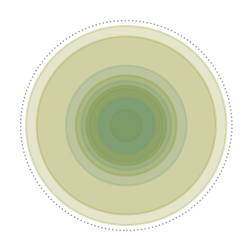

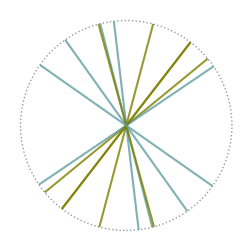

In [3]:
def plot_realizations(RS, n, colors, alpha):
    """Plot n randomly chosen realizations of RS, alternating between two colors."""
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.set_axis_off()
    ax.add_patch(ptch.Circle((0, 0), 1, fc="none", ec="black", ls=":", alpha=0.4))
    rng_ = np.random.default_rng(2026)
    for i, s in enumerate(rng_.choice(RS.sample, n)):
        s.plot(ax=ax, patch_args={"fc": colors[i % 2], "ec": colors[i % 2], "lw": 1.5, "alpha": alpha})
    return fig

colors = ["olive", "cadetblue"]

fig = plot_realizations(ball_RS, 10, colors, 0.2)
if SAVE_FIGURES: save_figure(fig, "images/uniqueness_sample1")
plt.show()

fig = plot_realizations(line_RS, 10, colors, 0.8)
if SAVE_FIGURES: save_figure(fig, "images/uniqueness_sample2")
plt.show()

### 3. Quantiles of the support function
For each direction $u$ (given by its angle) the plot shows the quantile of level $\alpha$
of the random variable $h(u; X)$, the support function of $X$ in direction $u$.
These curves are the support functions of the quantile sets.

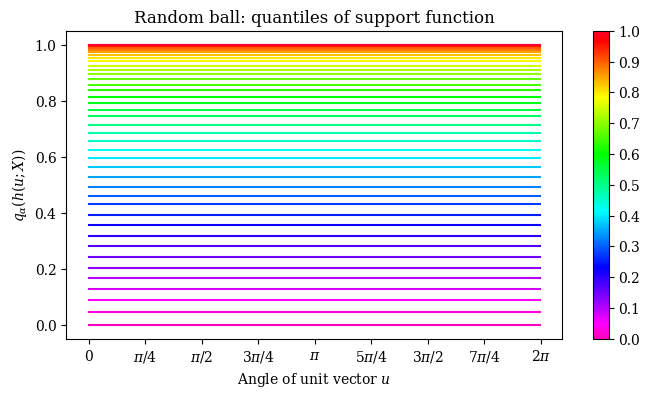

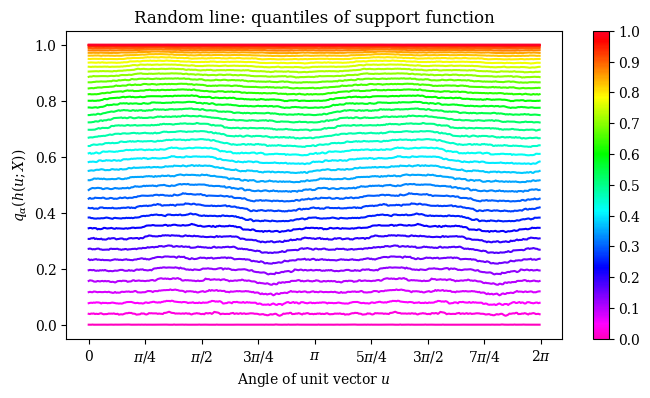

In [4]:
def plot_quantile_functions(supp_funcs, title):
    """Plot the alpha-quantiles of the support function as a function of the angle of u."""
    plt.figure(figsize=(8, 4))
    for a in ALPHAS:
        plt.plot(ANGLES, np.quantile(supp_funcs, a, axis=1), color=cm.gist_rainbow_r(a))
    plt.xticks(np.linspace(0, 2*np.pi, 9),
               [r"$0$", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$",
                r"$5\pi/4$", r"$3\pi/2$", r"$7\pi/4$", r"$2\pi$"])
    plt.title(title)
    plt.xlabel("Angle of unit vector $u$")
    plt.ylabel("$q_\\alpha(h(u;X))$")
    plt.colorbar(plt.cm.ScalarMappable(cmap="gist_rainbow_r"), ax=plt.gca(), ticks=ALPHAS[::4])
    plt.show()

plot_quantile_functions(ball_RS._supp_funcs, "Random ball: quantiles of support function")
plot_quantile_functions(line_RS._supp_funcs, "Random line: quantiles of support function")

### 4. Quantile sets $K_\alpha$
Quantiles for 21 equally spaced levels $\alpha \in [0, 1]$, colored by $\alpha$. First: ball, second: line.

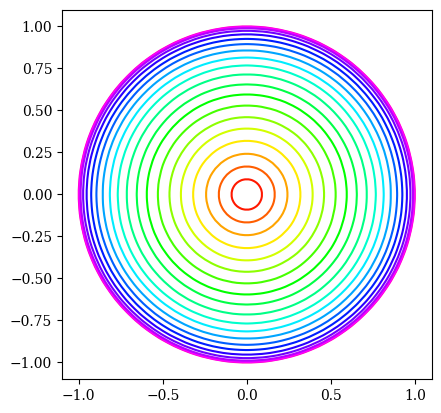

In [5]:
ball_RS.plot_quantiles(np.linspace(0, 1, 21))
if SAVE_FIGURES: save_figure(plt.gcf(), "images/uniqueness_quantiles", fig_size=(5, 5))
plt.show()

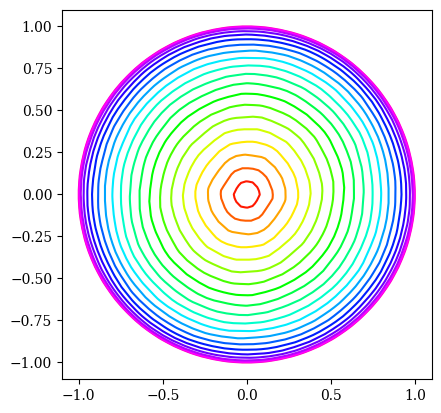

In [6]:
line_RS.plot_quantiles(np.linspace(0, 1, 21))
plt.show()